# 04 — Graph Neural Network sui grafi di visibilità

**Compito.** Stimare $H$ da una traiettoria di fBm, dando alla rete **il grafo di visibilità** della serie
invece della serie stessa.

**Domande**
1. Una GNN che vede il grafo intero recupera l'informazione su $H$ che la relazione analitica di Lacasa
   perdeva (notebook 02)? Fa meglio delle 16 feature del grafo costruite a mano (notebook 03)?
2. **Cosa conserva e cosa perde la rappresentazione a grafo?** Con il solo grado come feature dei nodi,
   la rete vede solo la topologia, invariante per riscalamento (e, per la NVG, per trend lineare): lo
   verifichiamo direttamente sulle previsioni della rete.
3. Aggiungere i **valori della serie** come feature dei nodi aiuta?

**Varianti** (stesso modello, stesso protocollo)

| Grafo | Feature dei nodi |
|---|---|
| NVG del fBm (come Lacasa et al.) | grado · grado + valori |
| HVG del fGn (il grafo con l'esponente $\lambda$ più informativo nel notebook 02) | grado · grado + valori |

**Contenuto:** 1. Configurazione · 2. Costruzione dei grafi · 3. Modello e scelta degli iperparametri ·
4. Ensemble delle quattro varianti · 5. Confronto sul test · 6. Invarianze: verifica sulle previsioni ·
7. Robustezza rispetto a $N$ · 8. Salvataggio · 9. Riepilogo

In [1]:
# --- Setup: su Colab clona il repository; ovunque installa ciò che manca ---
import os, sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Arminas00/stochastic-ml.git"
if IN_COLAB:
    repo = "/content/stochastic-ml"
    if os.path.exists(repo):
        subprocess.run(["git", "-C", repo, "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, repo], check=True)
    os.chdir(repo)

needed = ["numpy", "scipy", "pandas", "matplotlib", "sklearn", "ts2vg", "torch", "torch_geometric"]
missing = [m for m in needed if importlib.util.find_spec(m) is None]
if missing:
    print("Installo:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, os.getcwd())
print("Cartella di lavoro:", os.getcwd(), "| Colab:", IN_COLAB)

Cartella di lavoro: C:\Users\user\Downloads\AI_Project\stochastic-ml | Colab: False


## 1. Configurazione

La GNN è il modello più costoso del progetto. In `quick` (CPU) usiamo meno epoche e 2 seed: serve solo a
verificare che tutto giri (~30 minuti su un portatile). I numeri definitivi vengono dalla modalità `full` su GPU.

In [2]:
MODE = os.environ.get("SP_MODE", "quick")   # "quick" (CPU, verifica) o "full" (definitivo); il runner Colab imposta SP_MODE=full
SEED = 2026
DATA_DIR = "data"
FIG_DIR = "figures" if MODE == "quick" else f"figures_{MODE}"   # figure separate per modalità
N_BOOT = 1000

if MODE == "quick":
    N_SEEDS = 2
    GNN_GRID = [dict(hidden=32, n_layers=3), dict(hidden=64, n_layers=3)]
    TRAIN_KW = dict(max_epochs=12, patience=4, batch_size=128, lr=1e-3)
else:
    N_SEEDS = 3          # D-37: budget ridotto per i limiti di Colab (CNN: 5 seed, 40 epoche)
    GNN_GRID = [dict(hidden=32, n_layers=3), dict(hidden=64, n_layers=4)]
    TRAIN_KW = dict(max_epochs=25, patience=6, batch_size=128, lr=1e-3)

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import sp_utils as u

u.set_seed(SEED)
Path(FIG_DIR).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def savefig(name):
    plt.savefig(f"{FIG_DIR}/04_{name}.png", bbox_inches="tight", dpi=150)

DEV = u.get_device()
print("Dispositivo:", DEV)
CFG = u.MODES[MODE]
ds = u.load_or_make_fbm_dataset(MODE, SEED, DATA_DIR)
SPLITS = list(ds)
H = {s: ds[s]["H"].astype(np.float64) for s in SPLITS}

Dispositivo: cpu


## 2. Costruzione dei grafi

Per ogni serie costruiamo la NVG del fBm e l'HVG del fGn con `ts2vg` (verificata contro la definizione nel
notebook 01). Gli archi si conservano in forma compatta (interi a 32 bit, una sola direzione) e diventano
tensori solo quando si forma il batch (D-32).

In [4]:
GRAPHS = {}
KINDS = {"NVG(fBm)": ("nvg", "fbm"), "HVG(fGn)": ("hvg", "fgn")}
rows = []
for gname, (kind, series) in KINDS.items():
    GRAPHS[gname] = {}
    t0 = time.time()
    for s in SPLITS:
        GRAPHS[gname][s] = u.build_graphs(ds[s]["X"], kind, series)
    e_tr = GRAPHS[gname]["train"][0]
    rows.append({"grafo": gname, "secondi": time.time() - t0,
                 "archi medi (train)": np.mean([len(e) for e in e_tr]),
                 "grado medio (train)": 2 * np.mean([len(e) for e in e_tr]) / CFG["N"],
                 "MB archi (tutti gli split)": sum(e.nbytes for s in SPLITS for e in GRAPHS[gname][s][0]) / 1e6})
display(pd.DataFrame(rows).round(2))

,grafo,secondi,archi medi (train),grado medio (train),MB archi (tutti gli split)
0,NVG(fBm),27.28,3992.50,15.60,380.39
1,HVG(fGn),4.74,1009.77,3.94,83.97


**Feature dei nodi** (D-33):
- `grado`: $\log k$ del nodo, standardizzato con media e deviazione standard calcolate sui nodi del **train**;
- `grado+valori`: in più il valore della serie nel nodo, normalizzato per serie (media 0, deviazione 1),
  coerente con la scelta della CNN (D-26): non reintroduce l'ampiezza.

In [5]:
DATA = {}
for gname in KINDS:
    lk = np.log(np.concatenate(GRAPHS[gname]["train"][1]))
    mu, sd = lk.mean(), lk.std()
    for which in ["grado", "grado+valori"]:
        name = f"4 GNN {gname} {which}"
        DATA[name] = {s: u.GraphSet(GRAPHS[gname][s][0],
                                    u.node_features(GRAPHS[gname][s][1], GRAPHS[gname][s][2], which, mu, sd))
                      for s in SPLITS}
print(list(DATA))

['4 GNN NVG(fBm) grado', '4 GNN NVG(fBm) grado+valori', '4 GNN HVG(fGn) grado', '4 GNN HVG(fGn) grado+valori']


## 3. Modello e scelta degli iperparametri

**GIN** (Graph Isomorphism Network, Xu et al. 2019), `sp_utils.build_gnn`: strati di passaggio di messaggi con
aggregazione a **somma** sui vicini seguita da un MLP; dopo ogni strato si legge il grafo con media e massimo
sui nodi; le letture di tutti gli strati vanno in una testa densa. La somma (e non la media, come nella GCN)
permette alla rete di "contare" i vicini, cioè di vedere i gradi e le loro correlazioni: è l'informazione che
contiene $H$. Motivazioni e alternative in D-31.

Stesso protocollo della CNN (D-27): due configurazioni, scelte sul validation (sulla variante principale
NVG(fBm) con il solo grado, un seed); la configurazione scelta si usa per tutte e quattro le varianti.

In [6]:
import re
def fit_gnn(name, hp, seed, verbose=False):
    n_in = DATA[name]["train"].x[0].shape[1]
    m = u.build_gnn(n_in=n_in, **hp)
    # in full ogni modello addestrato si salva: dopo una disconnessione di Colab si riprende da lì (D-39)
    ck = (Path(DATA_DIR) / f"ckpt04_{MODE}" / f"{re.sub(r'[^A-Za-z0-9]+', '_', name)}_h{hp['hidden']}"
          f"_l{hp['n_layers']}_s{seed}.pt") if MODE == "full" else None
    return u.train_regressor(m, DATA[name]["train"], H["train"], DATA[name]["val"], H["val"],
                             seed=seed, verbose=verbose, checkpoint=ck, **TRAIN_KW)

MAIN = "4 GNN NVG(fBm) grado"
search_rows, best = [], None
for hp in GNN_GRID:
    t0 = time.time()
    m, hist = fit_gnn(MAIN, hp, SEED)
    val = min(h["rmse_val"] for h in hist)
    search_rows.append({**hp, "parametri": u.count_params(m), "epoche": len(hist), "RMSE val": val,
                        "s/epoca": np.mean([h["s"] for h in hist]), "secondi": time.time() - t0})
    if best is None or val < best[1]:
        best = (hp, val, hist)
display(pd.DataFrame(search_rows).round(4))
GNN_HP = best[0]
print("Configurazione scelta:", GNN_HP)

C:\Users\user\Downloads\AI_Project\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,hidden,n_layers,parametri,epoche,RMSE val,s/epoca,secondi
0,32,3,18148,11,0.0596,20.2549,228.1828
1,64,3,46404,12,0.0539,32.0971,385.3215


Configurazione scelta: {'hidden': 64, 'n_layers': 3}


## 4. Ensemble delle quattro varianti

In [7]:
PRED, PRED_STD, MEMBER_RMSE, HISTS, MODELS, TIMES = {}, {}, {}, {}, {}, {}
for name in DATA:
    t0 = time.time()
    members, hists = [], []
    for k in range(N_SEEDS):
        m, h = fit_gnn(name, GNN_HP, SEED + 100 * k)
        members.append(m); hists.append(h)
    TIMES[name] = time.time() - t0
    MODELS[name], HISTS[name] = members, hists
    P = {s: np.stack([u.predict(m, DATA[name][s]) for m in members]) for s in SPLITS}
    PRED[name] = {s: P[s].mean(0) for s in SPLITS}
    PRED_STD[name] = {s: P[s].std(0) for s in SPLITS}
    MEMBER_RMSE[name] = [u.regression_metrics(H["val"], P["val"][k])["RMSE"] for k in range(N_SEEDS)]
    print(f"{name:<34} membri (val) {np.round(MEMBER_RMSE[name], 4)}  ensemble (val) "
          f"{u.regression_metrics(H['val'], PRED[name]['val'])['RMSE']:.4f}  ({TIMES[name]:.0f} s)")

4 GNN NVG(fBm) grado               membri (val) [0.0513 0.0593]  ensemble (val) 0.0546  (598 s)


4 GNN NVG(fBm) grado+valori        membri (val) [0.0471 0.0466]  ensemble (val) 0.0464  (800 s)


4 GNN HVG(fGn) grado               membri (val) [0.0831 0.0987]  ensemble (val) 0.0880  (427 s)


4 GNN HVG(fGn) grado+valori        membri (val) [0.0388 0.0371]  ensemble (val) 0.0375  (386 s)


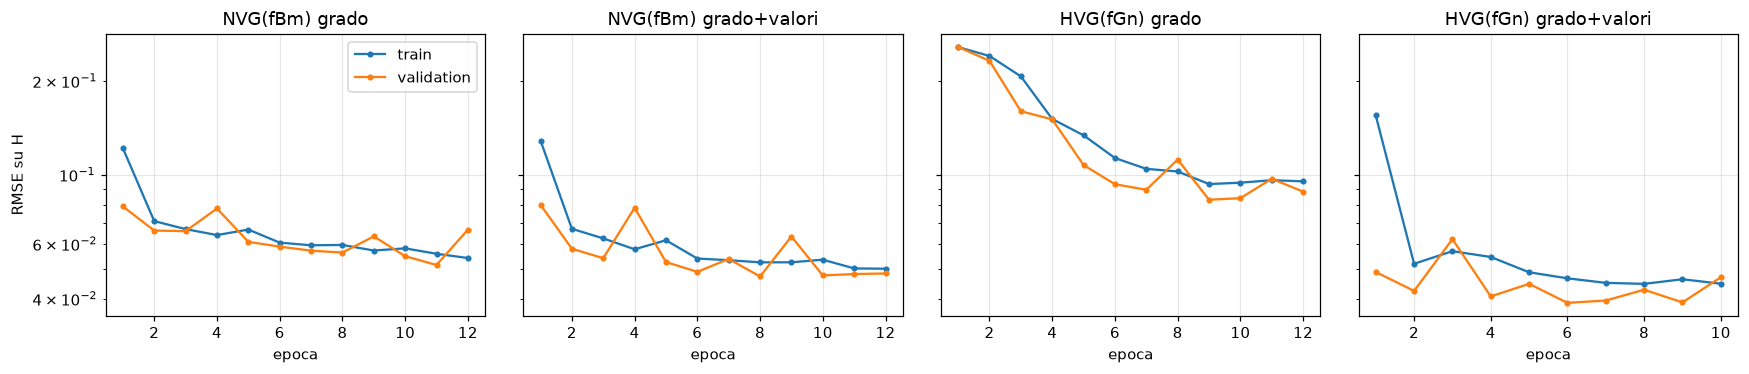

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, name in zip(axes, DATA):
    h = pd.DataFrame(HISTS[name][0])
    ax.plot(h["epoch"], h["rmse_train"], "o-", ms=3, label="train")
    ax.plot(h["epoch"], h["rmse_val"], "o-", ms=3, label="validation")
    ax.set(title=name.replace("4 GNN ", ""), xlabel="epoca", yscale="log")
axes[0].set_ylabel("RMSE su H"); axes[0].legend()
plt.tight_layout(); savefig("curve_apprendimento"); plt.show()

## 5. Confronto sul test set

Riferimenti dagli altri notebook, sullo stesso test set: baseline, DFA, relazione di Lacasa (approccio 2a),
gradient boosting sulle 16 feature del grafo, CNN (normalizzata per serie).

In [9]:
p02 = np.load(Path(DATA_DIR) / f"preds02_{MODE}_seed{SEED}.npz")
p03 = np.load(Path(DATA_DIR) / f"preds03_{MODE}_seed{SEED}.npz")
REF = {"0 baseline (media)": p02, "1a DFA": p02, "2a NVG(fBm) Lacasa": p02,
       "3-GBT feature grafo": p03, "3 CNN (per_serie)": p03}
for ref, src in REF.items():
    PRED[ref] = {s: src[f"{ref}__{s}"] for s in SPLITS}

order = list(REF) + list(DATA)
rows = []
for name in order:
    m = u.regression_metrics(H["test"], PRED[name]["test"])
    lo, hi = u.bootstrap_ci(H["test"], PRED[name]["test"], "RMSE", n_boot=N_BOOT, seed=SEED)
    rows.append({"metodo": name, "RMSE": m["RMSE"], "IC 95% RMSE": f"[{lo:.3f}, {hi:.3f}]", "MAE": m["MAE"],
                 "bias": m["bias"], "R2": m["R2"], "std previsioni": m["std previsioni"],
                 "RMSE val membri": (f"{np.mean(MEMBER_RMSE[name]):.4f} ± {np.std(MEMBER_RMSE[name]):.4f}"
                                     if name in MEMBER_RMSE else "")})
df_res = pd.DataFrame(rows).set_index("metodo")
display(df_res.round(4))

,RMSE,IC 95% RMSE,MAE,bias,R2,std previsioni,RMSE val membri
metodo,,,,,,,
0 baseline (media),0.2591,"[0.254, 0.264]",0.2234,0.0001,-0.0000,0.0000,
1a DFA,0.0533,"[0.051, 0.055]",0.0414,0.0049,0.9577,0.2524,
2a NVG(fBm) Lacasa,1.1770,"[1.118, 1.250]",0.8544,-0.8446,-19.6301,0.6880,
3-GBT feature grafo,0.0369,"[0.036, 0.038]",0.0293,-0.0003,0.9797,0.2553,
3 CNN (per_serie),0.0308,"[0.030, 0.032]",0.0244,-0.0055,0.9858,0.2602,
4 GNN NVG(fBm) grado,0.0518,"[0.050, 0.054]",0.0402,-0.0019,0.9600,0.2479,0.0553 ± 0.0040
4 GNN NVG(fBm) grado+valori,0.0452,"[0.044, 0.047]",0.0353,-0.0026,0.9696,0.2538,0.0469 ± 0.0003
4 GNN HVG(fGn) grado,0.0914,"[0.089, 0.094]",0.0735,-0.0249,0.8756,0.2325,0.0909 ± 0.0078
4 GNN HVG(fGn) grado+valori,0.0361,"[0.035, 0.037]",0.0291,-0.0023,0.9806,0.2505,0.0380 ± 0.0008


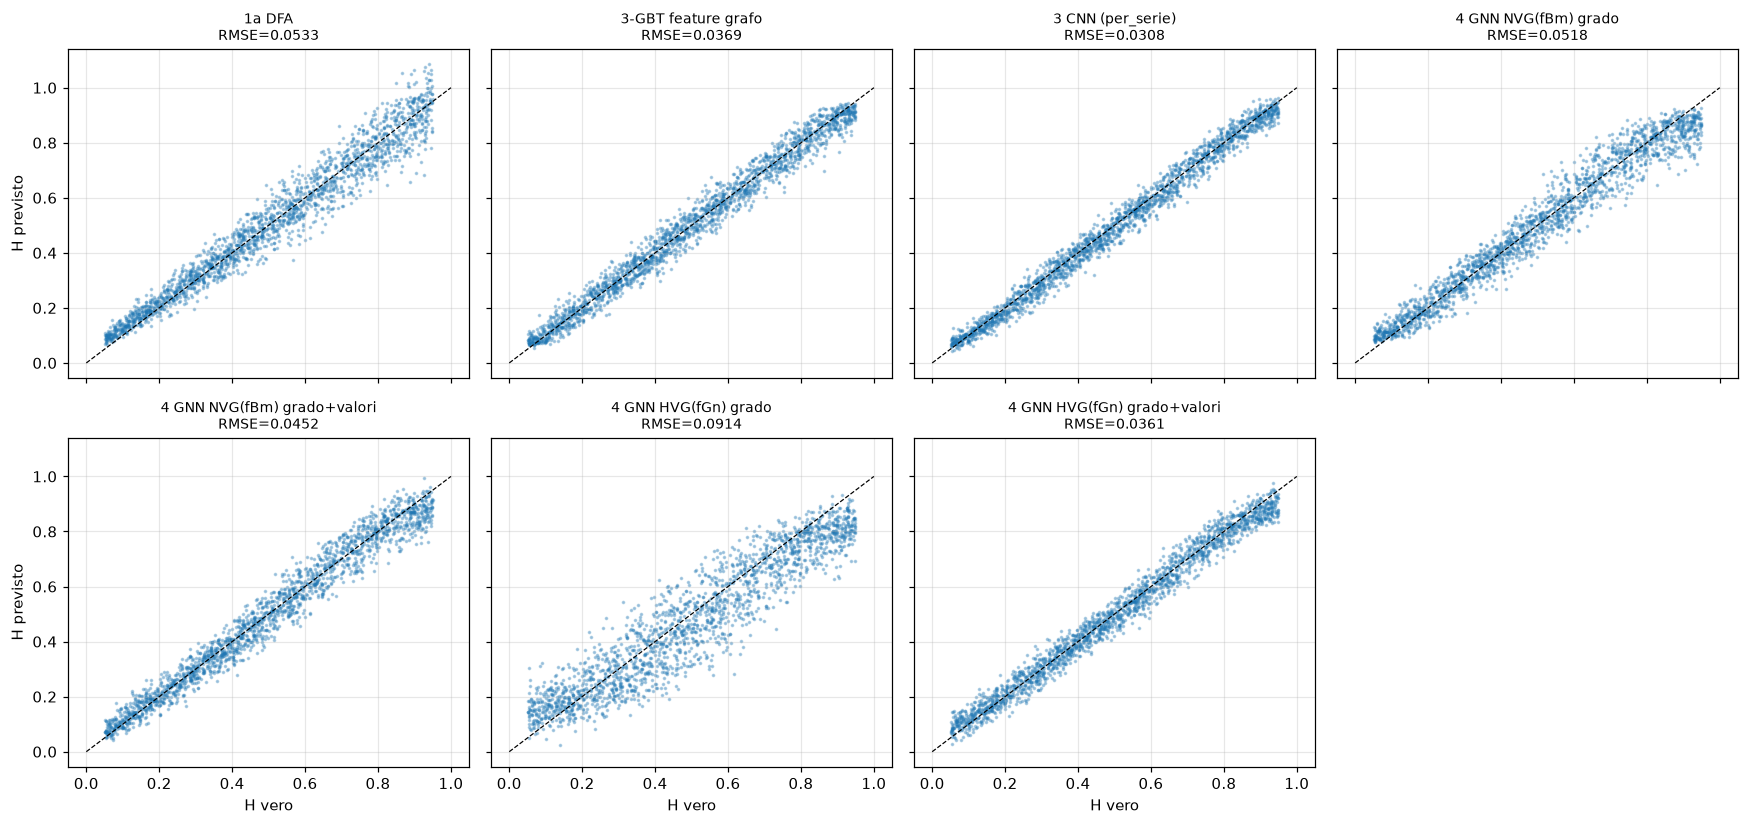

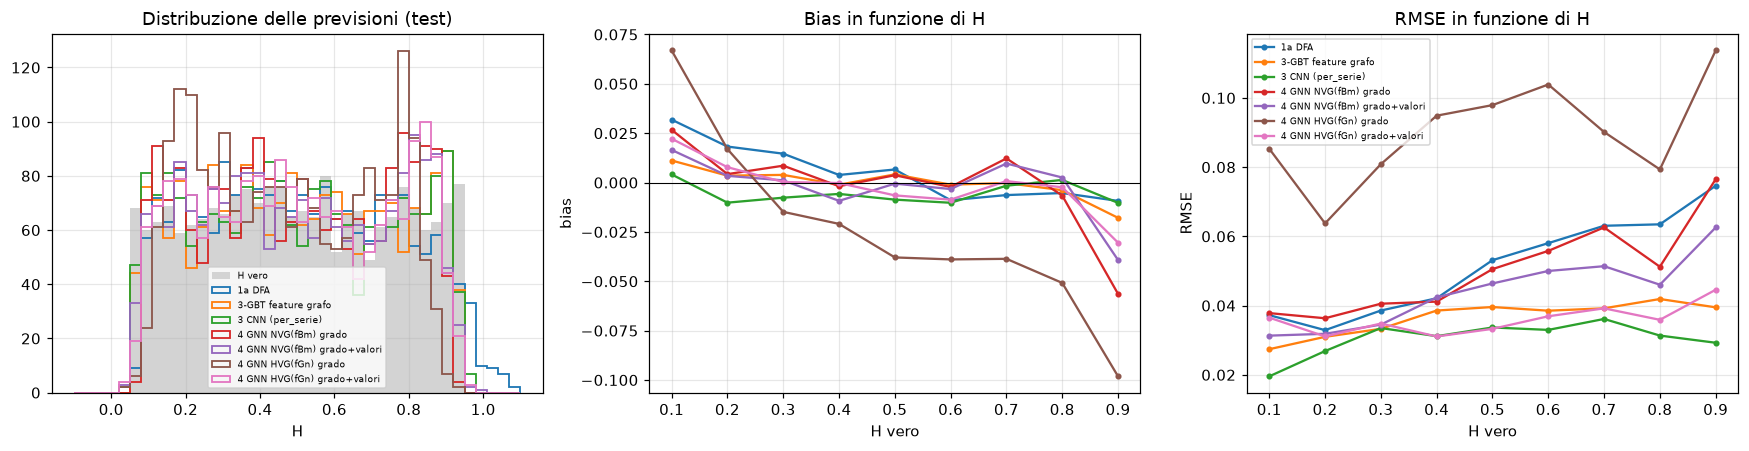

In [10]:
show = ["1a DFA", "3-GBT feature grafo", "3 CNN (per_serie)"] + list(DATA)
fig, axes = plt.subplots(2, 4, figsize=(16, 7.6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, show):
    ax.scatter(H["test"], PRED[name]["test"], s=2, alpha=0.3)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name}\nRMSE={df_res.loc[name, 'RMSE']:.4f}", fontsize=9)
axes.flat[-1].axis("off")
for ax in axes[-1]: ax.set_xlabel("H vero")
for ax in axes[:, 0]: ax.set_ylabel("H previsto")
plt.tight_layout(); savefig("scatter"); plt.show()

bins = np.linspace(0.05, 0.95, 10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(H["test"], bins=40, range=(-0.1, 1.1), histtype="stepfilled", color="lightgrey", label="H vero")
for name in show:
    axes[0].hist(PRED[name]["test"], bins=40, range=(-0.1, 1.1), histtype="step", lw=1.2, label=name)
    be = u.binned_errors(H["test"], PRED[name]["test"], bins)
    axes[1].plot(be["centers"], be["bias"], "o-", ms=3, label=name)
    axes[2].plot(be["centers"], be["rmse"], "o-", ms=3, label=name)
axes[0].set(xlabel="H", title="Distribuzione delle previsioni (test)"); axes[0].legend(fontsize=6)
axes[1].axhline(0, color="k", lw=0.7); axes[1].set(xlabel="H vero", ylabel="bias", title="Bias in funzione di H")
axes[2].set(xlabel="H vero", ylabel="RMSE", title="RMSE in funzione di H"); axes[2].legend(fontsize=6)
plt.tight_layout(); savefig("errore_vs_H"); plt.show()

## 6. Invarianze: verifica sulle previsioni dei modelli

Nel notebook 01 abbiamo verificato le invarianze **dei grafi**. Qui verifichiamo che passino ai **modelli
addestrati**: trasformiamo 500 serie del test e misuriamo di quanto cambiano le previsioni.

- **riscalamento** dell'ampiezza: fGn → $3.7\cdot$fGn (equivale a fBm → $3.7\cdot$fBm);
- **trend lineare** sul fBm: $W_H(t)\to W_H(t) + b\,t$, cioè fGn → fGn $+\,b$ (deriva costante), con $b$ pari a
  due deviazioni standard della serie distribuite su tutta la lunghezza.

Attenzione a **su quale serie è costruito il grafo**: un trend lineare del fBm è una *costante* aggiunta al fGn.

| Modello | riscalamento | deriva | perché |
|---|---|---|---|
| GNN NVG(fBm), grado | invariante | invariante | la NVG è invariante per $a x + b t + c$ (notebook 01) |
| GNN NVG(fBm), grado+valori | invariante | **cambia** | i valori del fBm normalizzati per serie cambiano forma con il trend |
| GNN HVG(fGn), grado | invariante | invariante | sul fGn la deriva è una costante: trasformazione monotona |
| GNN HVG(fGn), grado+valori | invariante | invariante | la normalizzazione per serie toglie la costante |
| CNN per serie | invariante | invariante | la normalizzazione toglie media e scala del fGn |
| CNN globale | **cambia** | **cambia** | vede l'ampiezza e la media |

Per i modelli "invarianti" ci aspettiamo variazioni nulle (a meno dell'arrotondamento in virgola mobile).

In [11]:
n_inv = 500
X0 = ds["test"]["X"][:n_inv].astype(np.float64)
b = 2 * u.fbm_from_fgn(X0).std(axis=1, keepdims=True) / CFG["N"]
TRANSF = {"riscalamento ×3.7": 3.7 * X0, "deriva (trend lineare del fBm)": X0 + b}

def predict_models(name, X):
    """Ricostruisce la rappresentazione della serie trasformata e predice con l'ensemble del modello."""
    if name.startswith("4 GNN"):
        gname = "NVG(fBm)" if "NVG" in name else "HVG(fGn)"
        kind, series = KINDS[gname]
        e, d, v = u.build_graphs(X, kind, series)
        lk = np.log(np.concatenate(GRAPHS[gname]["train"][1]))
        which = "grado+valori" if "valori" in name else "grado"
        G = u.GraphSet(e, u.node_features(d, v, which, lk.mean(), lk.std()))
        return np.mean([u.predict(m, G) for m in MODELS[name]], axis=0)
    how = "per_serie" if "per_serie" in name else "globale"
    return np.mean([u.predict(m, u.normalize_series(X, how, CNN_SCALE)) for m in CNN_MODELS[how]], axis=0)

# modelli CNN del notebook 03
st = torch.load(Path(DATA_DIR) / f"cnn03_{MODE}_seed{SEED}.pt", map_location=DEV)
cnn_hp = {how: (st[how][0]["features.0.weight"].shape[0]) for how in st}
CNN_MODELS = {}
for how, states in st.items():
    ms = []
    for sd_ in states:
        m = u.build_model("cnn", width=cnn_hp[how]).to(DEV); m.load_state_dict(sd_)
        m.y_mu, m.y_sd = float(H["train"].mean()), float(H["train"].std()); ms.append(m)
    CNN_MODELS[how] = ms
CNN_SCALE = float(ds["train"]["X"].std())

rows = []
for name in list(DATA) + ["3 CNN (per_serie)", "3 CNN (globale)"]:
    p0 = predict_models(name, X0)
    r = {"modello": name}
    for tname, Xt in TRANSF.items():
        r[f"{tname}: max |Δ previsione|"] = np.abs(predict_models(name, Xt) - p0).max()
        r[f"{tname}: RMSE dopo"] = np.sqrt(np.mean((predict_models(name, Xt) - H["test"][:n_inv]) ** 2))
    r["RMSE prima"] = np.sqrt(np.mean((p0 - H["test"][:n_inv]) ** 2))
    rows.append(r)
df_inv = pd.DataFrame(rows).set_index("modello")
display(df_inv.round(4))

,riscalamento ×3.7: max |Δ previsione|,riscalamento ×3.7: RMSE dopo,deriva (trend lineare del fBm): max |Δ previsione|,deriva (trend lineare del fBm): RMSE dopo,RMSE prima
modello,,,,,
4 GNN NVG(fBm) grado,0.0000,0.0533,0.0000,0.0533,0.0533
4 GNN NVG(fBm) grado+valori,0.0000,0.0453,0.0829,0.0489,0.0453
4 GNN HVG(fGn) grado,0.0000,0.0854,0.0000,0.0854,0.0854
4 GNN HVG(fGn) grado+valori,0.0000,0.0369,0.0000,0.0369,0.0369
3 CNN (per_serie),0.0000,0.0306,0.0000,0.0306,0.0306
3 CNN (globale),0.5411,0.3628,0.0357,0.0299,0.0289


*Nota tecnica.* La CNN salvata nel notebook 03 contiene solo i pesi; media e deviazione del target usate per
standardizzarlo sono quelle del train ($\bar H$, $\sigma_H$), ricalcolate qui identiche.

## 7. Robustezza rispetto alla lunghezza $N$

Come la CNN, la GNN ha pooling globale e accetta grafi di qualunque dimensione. La standardizzazione di
$\log k$ però usa la media del train, e nella NVG il grado medio cresce con $N$.

N,128,256,512,1024,2048
metodo,,,,,
1a DFA,0.101,0.072,0.053,0.040,0.034
3 CNN (per_serie),0.079,0.048,0.031,0.028,0.031
3-GBT feature grafo,0.089,0.054,0.037,0.030,0.023
4 GNN HVG(fGn) grado,0.167,0.121,0.091,0.067,0.061
4 GNN HVG(fGn) grado+valori,0.085,0.057,0.036,0.036,0.045
4 GNN NVG(fBm) grado,0.164,0.096,0.052,0.054,0.063
4 GNN NVG(fBm) grado+valori,0.165,0.091,0.045,0.053,0.070


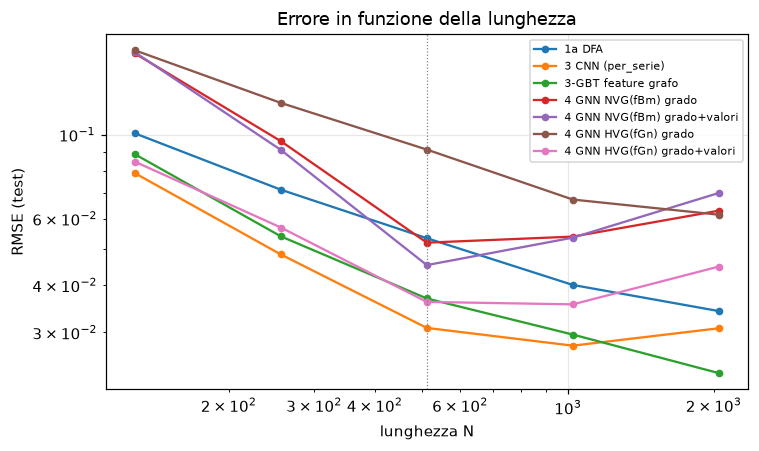

In [12]:
lengths = sorted([CFG["N"]] + list(CFG["robust_lengths"]))
split_of = {L: ("test" if L == CFG["N"] else f"test_N{L}") for L in lengths}
rob = ["1a DFA", "3 CNN (per_serie)", "3-GBT feature grafo"] + list(DATA)
rows = [{"metodo": n, "N": L, "RMSE": u.regression_metrics(H[split_of[L]], PRED[n][split_of[L]])["RMSE"]}
        for n in rob for L in lengths]
df_rob = pd.DataFrame(rows).pivot(index="metodo", columns="N", values="RMSE")
display(df_rob.round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
for n in rob:
    ax.plot(lengths, df_rob.loc[n, lengths], "o-", ms=4, label=n)
ax.axvline(CFG["N"], color="grey", lw=0.8, ls=":")
ax.set(xscale="log", yscale="log", xlabel="lunghezza N", ylabel="RMSE (test)", title="Errore in funzione della lunghezza")
ax.legend(fontsize=7); plt.tight_layout(); savefig("rmse_vs_N"); plt.show()

## 8. Salvataggio

In [13]:
out = Path(DATA_DIR) / f"preds04_{MODE}_seed{SEED}.npz"
np.savez_compressed(out, **{f"{n}__{s}": v for n, d in PRED.items() if n in DATA for s, v in d.items()},
                    **{f"STD::{n}__{s}": v for n, d in PRED_STD.items() for s, v in d.items()})
df_res.to_csv(Path(DATA_DIR) / f"results04_{MODE}.csv")
torch.save({n: [m.state_dict() for m in ms] for n, ms in MODELS.items()}, Path(DATA_DIR) / f"gnn04_{MODE}_seed{SEED}.pt")
print("Salvato", out, "| tempi (s):", {k: round(v) for k, v in TIMES.items()})

Salvato data\preds04_quick_seed2026.npz | tempi (s): {'4 GNN NVG(fBm) grado': 598, '4 GNN NVG(fBm) grado+valori': 800, '4 GNN HVG(fGn) grado': 427, '4 GNN HVG(fGn) grado+valori': 386}


## 9. Riepilogo

In [14]:
for name in DATA:
    r = df_res.loc[name, "RMSE"]
    print(f"{name:<34} RMSE {r:.4f} | vs DFA {100 * (r / df_res.loc['1a DFA', 'RMSE'] - 1):+.0f}% "
          f"| vs feature grafo {100 * (r / df_res.loc['3-GBT feature grafo', 'RMSE'] - 1):+.0f}% "
          f"| vs CNN {100 * (r / df_res.loc['3 CNN (per_serie)', 'RMSE'] - 1):+.0f}%")

4 GNN NVG(fBm) grado               RMSE 0.0518 | vs DFA -3% | vs feature grafo +41% | vs CNN +68%
4 GNN NVG(fBm) grado+valori        RMSE 0.0452 | vs DFA -15% | vs feature grafo +23% | vs CNN +47%
4 GNN HVG(fGn) grado               RMSE 0.0914 | vs DFA +72% | vs feature grafo +148% | vs CNN +196%
4 GNN HVG(fGn) grado+valori        RMSE 0.0361 | vs DFA -32% | vs feature grafo -2% | vs CNN +17%


### Cosa abbiamo imparato (modalità quick: N = 512, 4000 serie di train, 2 semi per variante)

**Prestazioni sul test (RMSE su H, IC 95% bootstrap).**
- La variante migliore è **GNN HVG(fGn) grado+valori: 0.036 [0.035, 0.037]**, scelta anche dal validation (0.038). È alla pari con il GBT sulle 16 feature di grafo (0.037), meglio della DFA (0.053, −32%), ma peggio della CNN sulla serie grezza (0.031, +17%).
- Con il **solo grado** (cioè solo la topologia del grafo) le GNN fanno peggio: NVG 0.052 (come la DFA), HVG 0.091. Il grafo da solo contiene informazione su H, ma una GNN con 3 strati di message passing non la estrae meglio delle feature fatte a mano: il GBT sulle feature di grafo arriva a 0.037.
- Aggiungere i valori della serie ai nodi aiuta molto per l'HVG (0.091 → 0.036) e poco per l'NVG (0.052 → 0.045). L'HVG(fGn) è un grafo sparso (grado medio ≈ 4): con i valori diventa sostanzialmente una rete convoluzionale su un supporto irregolare.
- Costo: 6–13 minuti per variante su CPU, contro circa 2 minuti per la CNN. A parità di dati, la GNN costa di più e non è migliore.

**Invarianze (test fisico chiave, 500 serie di test).**
- Con nodi = solo grado, le previsioni restano **identiche** (max |Δ| = 0) sia dopo un riscalamento ×3.7 sia dopo l'aggiunta di una deriva lineare al fBm. Questo conferma sul modello addestrato le invarianze del grafo verificate nel notebook 01.
- Con i valori della serie (normalizzati per serie), il riscalamento non cambia nulla. La deriva cambia le previsioni della GNN NVG grado+valori (max |Δ| = 0.083): i valori sui nodi rompono l'invarianza dell'NVG rispetto al trend.
- Per confronto, la CNN con normalizzazione globale cambia previsione sotto riscalamento (max |Δ| = 0.54, RMSE 0.029 → 0.36). Usa l'ampiezza, che non dovrebbe contenere informazione su H (D-19, D-26).

**Robustezza alla lunghezza N** (addestramento solo a N = 512).
- Le GNN generalizzano peggio della CNN e del GBT sulle feature di grafo: a N = 2048 l'RMSE **sale** (NVG 0.063–0.070, HVG+valori 0.045), mentre il GBT sulle feature di grafo scende a 0.023.
- Lettura plausibile: grado e readout (media + max) dipendono dalla dimensione del grafo, e il grado massimo cresce con N. La GNN impara la scala di N = 512 invece di una proprietà intensiva.

**Note di onestà.**
- La scelta LayerNorm al posto di BatchNorm (D-35) è stata fatta dopo aver visto i numeri di test della prima esecuzione. È motivata dal validation instabile, ma è registrata.
- Gli iperparametri sono stati scelti sulla sola variante principale (D-34), con una griglia di 2 configurazioni: lo stesso sforzo dato alla CNN.
- In modalità quick ci sono solo 2 semi: la dispersione tra i membri (es. 0.055 ± 0.004 per NVG grado) è indicativa. I numeri definitivi verranno dalla modalità full su Colab.

**Conclusione.** Nella sua forma migliore (HVG + valori), la GNN sul grafo di visibilità è competitiva con le feature di grafo fatte a mano, ma non batte la CNN, costa di più e generalizza peggio in N. Per la regola del corso ("a parità di prestazioni, il più semplice") non è il modello principale. Il suo valore è soprattutto fisico: con il solo grado è un estimatore **dimostrabilmente invariante** per ampiezza e deriva. Nel notebook 05 la migliore variante (HVG grado+valori) viene provata come ibrido con le stime fisiche.